In [120]:
import torch
import os
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import scipy
import matplotlib.transforms as transforms

base_path = "./"

In [121]:
param_vals = {"distr": "UNI"}

In [147]:
ids = [2,5,6,7,8,9] if param_vals["distr"] == "Normal" else [1,10,11,12,13,14]

In [148]:
save_dir = f"{base_path}/results/simulations/"
log_file = os.path.join(save_dir, 'parameter_log.csv')
param_log = pd.read_csv(log_file)

In [149]:
eps_vals = [param_log[param_log["ID"] == i]["eps"].item() for i in ids]

In [150]:
eps_vals

[0.0, 0.5, 0.3, 0.7, 0.9, 0.1]

In [151]:
res = {eps_vals[k]: torch.load(f"{base_path}/results/simulations/results_{i}.pt", weights_only=False)['metrics']['flowgem'] for k,i in enumerate(ids)}

In [152]:
## Create dataframe with all results
rows = []
for eps, recs in res.items():
    for r in recs:
        rows.append({**r, "eps": eps})

results_df = pd.DataFrame(rows)

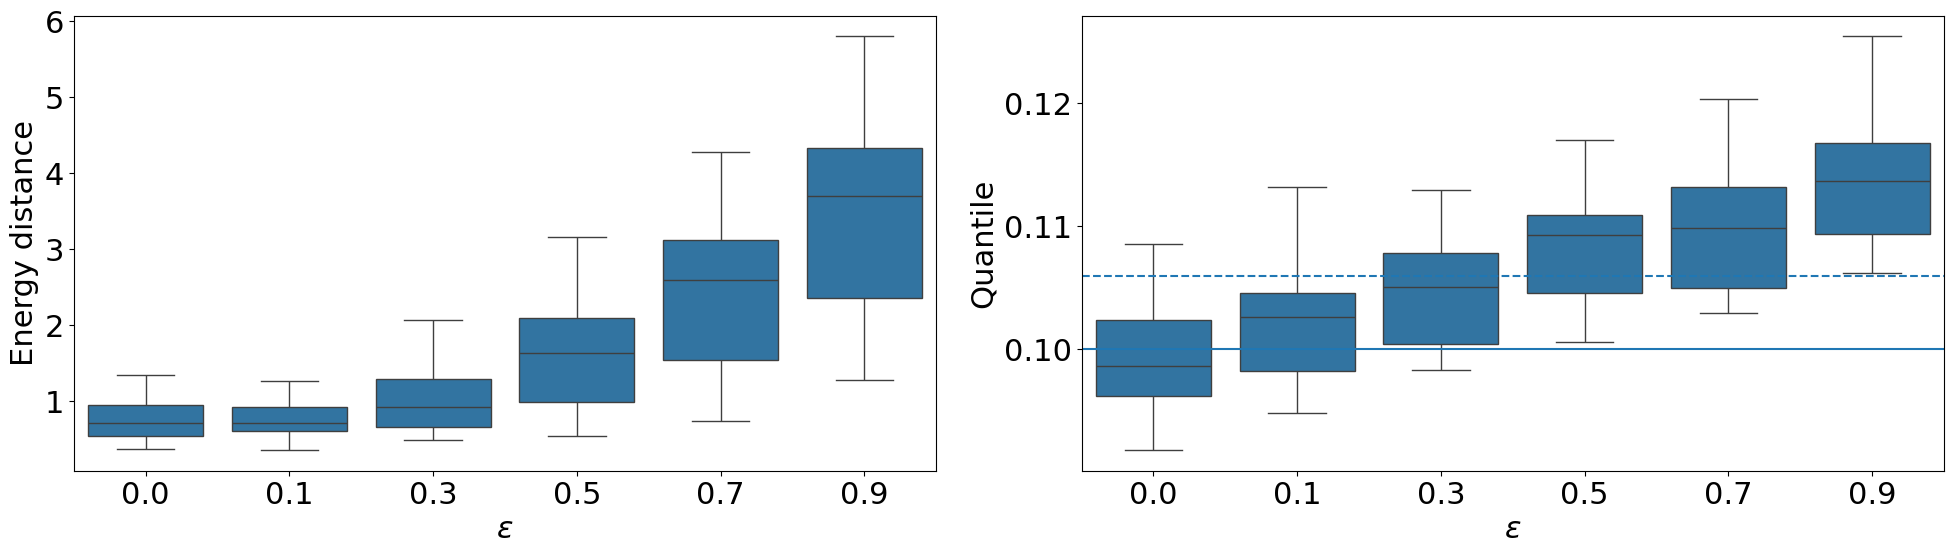

In [153]:
def boxplot(df, col, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    df_max = df

    # def make_palette(df, col="method", highlight="flowgem", highlight_color="orange", default_color="#4C72B0"):
    #     methods = df[col].unique()
    #     return {m: highlight_color if m == highlight else default_color for m in methods}
    sns.boxplot(x="eps", y=col, data=df_max, ax=ax, showfliers=False)#, palette=make_palette(df_max))
    ax.set_xlabel("")
    #ax.set_title(f"{col} distribution per method")
    ax.set_ylabel(col)
    if col == "quantile":
        if param_vals["distr"] == "UNI":
            ax.axhline(0.1)
            ax.axhline(0.106, linestyle='--')
        elif param_vals["distr"] == "Normal":
            ax.axhline(scipy.stats.norm.ppf(0.1))

    if ax is None:
        plt.show()

plt.rcParams.update({'font.size': 22})

fig, axes = plt.subplots(1, 2, figsize=(20, 6))

for ax, col in zip(axes, ["energy.indep", "quantile"]):
    boxplot(results_df, col, ax=ax)

axes[0].set_ylabel("Energy distance")
axes[1].set_ylabel("Quantile")
axes[0].set_xlabel("$\\varepsilon$")
axes[1].set_xlabel("$\\varepsilon$")

# axes[0].set_yscale("log")
# if param_vals["distr"] == 'UNI':
#     axes[0].set_yticks([0.5, 1, 2.5, 5, 10, 25, 50, 100], [0.5, 1, 2.5, 5, 10, 25, 50, 100])
#     axes[0].set_ylim(bottom=0.25, top=110)
#     axes[1].set_ylim(bottom=0.05, top=0.15)
# else:
#     axes[0].set_yticks([2.5, 5, 10, 25, 50, 100], [2.5, 5, 10, 25, 50, 100])
    # axes[0].set_ylim(bottom=1.25, top=500)


# axes[0].set_xticklabels([title_dict[tick.get_text()] for tick in ax.get_xticklabels()])
# axes[1].set_xticklabels([title_dict[tick.get_text()] for tick in ax.get_xticklabels()])

# Offset every other label downward
# for k in [0,1]:
#   for i, label in enumerate(axes[k].get_xticklabels()):
#       if i % 2 != 0:  # every other label
#           label.set_transform(label.get_transform() +
#                               transforms.ScaledTranslation(0, -0.3, fig.dpi_scale_trans))

plt.tight_layout()
plt.savefig(f"{base_path}/results/simulations/boxplots{param_vals["distr"]}.png", dpi=150, bbox_inches="tight")
plt.show()

In [155]:
out = (results_df
       .groupby('eps', as_index=False)
       .agg(energy_mean=('energy.indep', 'mean'),
            quantile_mean=('quantile', 'mean'),
            n=('energy', 'size'))
      )

print(out.sort_values('eps'))


   eps  energy_mean  quantile_mean   n
0  0.0     0.804230       0.099321  20
1  0.1     0.792197       0.102046  20
2  0.3     1.045544       0.104694  20
3  0.5     1.637780       0.108149  20
4  0.7     2.410341       0.109815  20
5  0.9     3.518101       0.113883  20
